In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# Display dataset information
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [3]:
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


## 2. Data Cleaning and Preprocessing

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check unique values in TotalCharges
print("\nTotalCharges Data Type:", df['TotalCharges'].dtype)
print("Blank TotalCharges:", (df['TotalCharges'].str.strip() == '').sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64



Duplicate Records: 0

TotalCharges Data Type: str
Blank TotalCharges: 11


In [5]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

print("TotalCharges Data Type:", df['TotalCharges'].dtype)
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

TotalCharges Data Type: float64
Missing TotalCharges: 11


In [6]:
df.drop('customerID', axis=1, inplace=True)

print("Updated Dataset Shape:", df.shape)

Updated Dataset Shape: (7043, 20)


Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


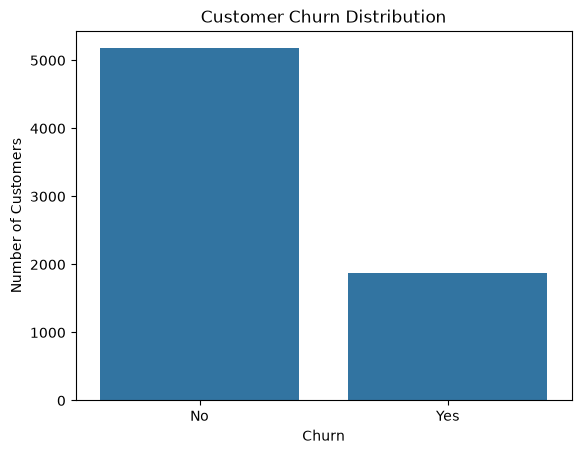

In [7]:
print("Churn Distribution:")
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [8]:
# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify missing values
print("Total Missing Values:", df.isnull().sum().sum())

print("Updated Dataset Shape:", df.shape)

Total Missing Values: 0
Updated Dataset Shape: (7043, 20)


In [9]:
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


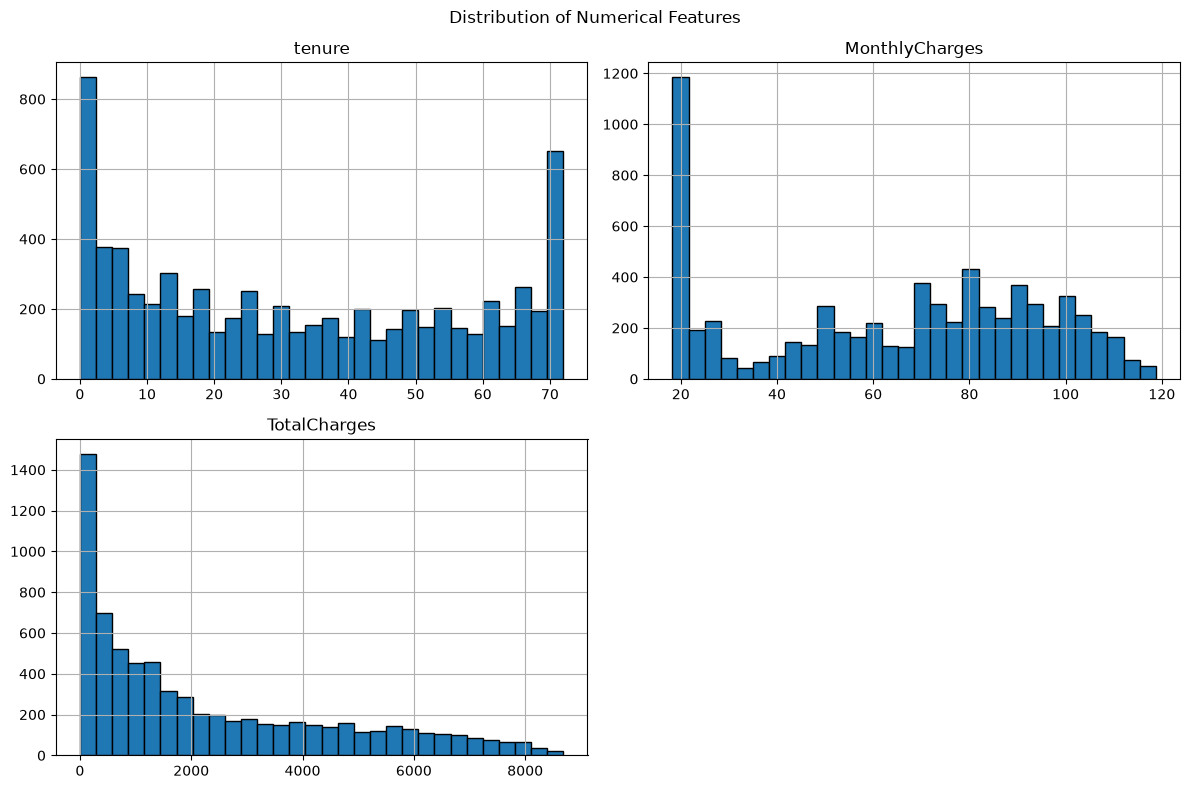

In [10]:
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

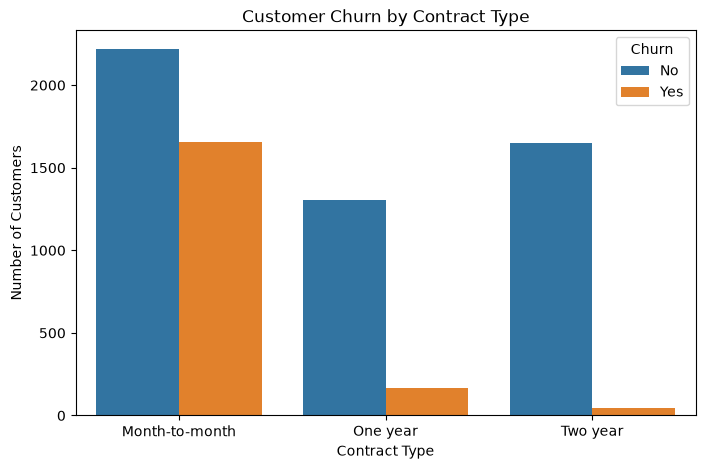

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

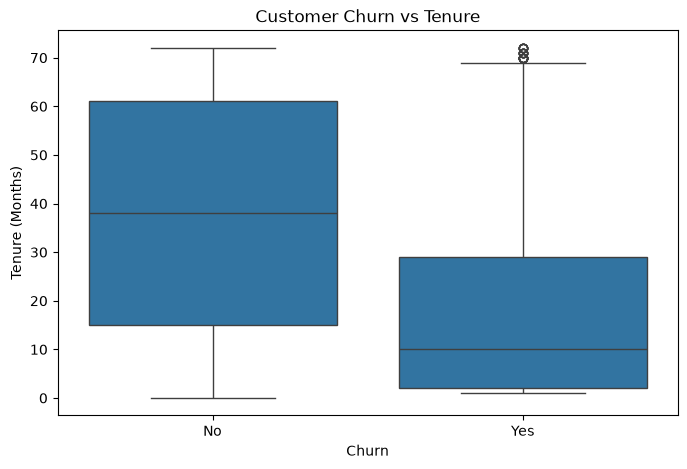

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

plt.title('Customer Churn vs Tenure')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

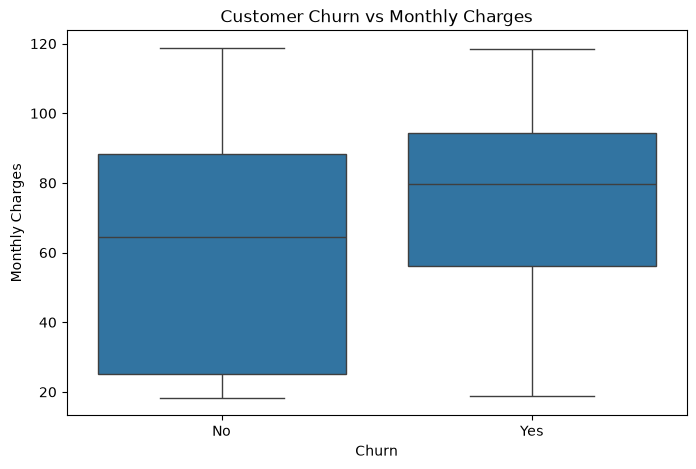

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Customer Churn vs Monthly Charges')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

## 5. Feature Selection and Train-Test Split

In [14]:
# Separate input features and target variable
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'No': 0, 'Yes': 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [15]:
# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 4
Total Categorical Features: 15


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [18]:
# Numerical feature preprocessing
numeric_transformer = StandardScaler()

# Categorical feature preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [19]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (5634, 45)
Testing Data Shape: (1409, 45)


In [20]:
# Initialize SMOTE
smote = SMOTE(random_state=42)

# Balance training dataset
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64

Balanced Training Shape: (8278, 45)


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

In [22]:
# Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

# Train the model
rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [23]:
# Predict churn
rf_predictions = rf_model.predict(X_test_processed)

# Predict probabilities
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [24]:
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)
rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest Performance:")
print("--------------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC Score:", round(rf_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Performance:
--------------------------------
Accuracy: 0.7736
Precision: 0.5766
Recall: 0.5535
F1 Score: 0.5648
ROC-AUC Score: 0.8185

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1035
           1       0.58      0.55      0.56       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.71      1409
weighted avg       0.77      0.77      0.77      1409



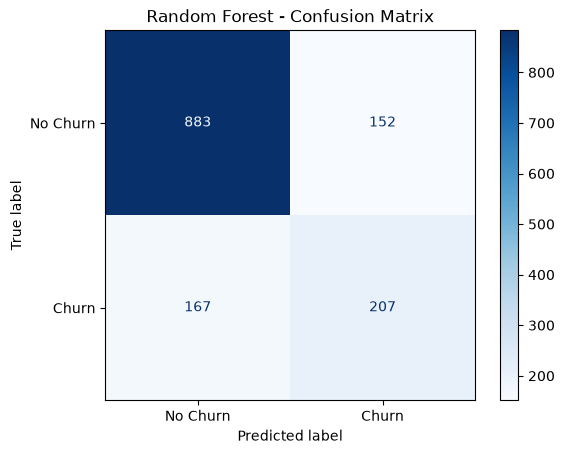

In [25]:
cm = confusion_matrix(y_test, rf_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.show()

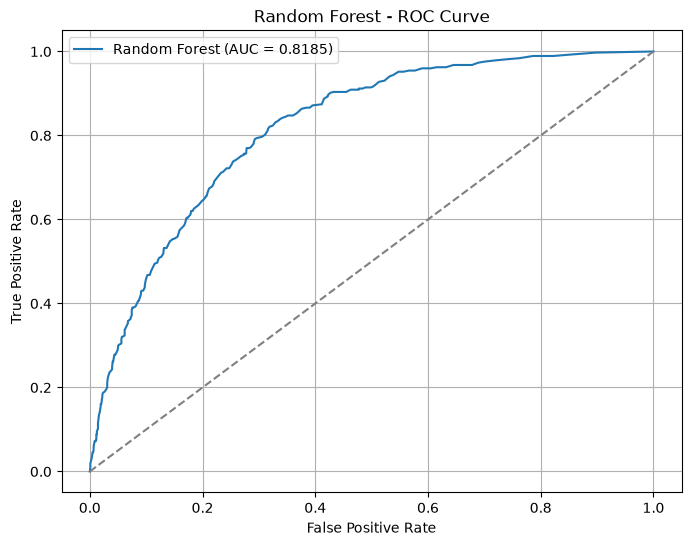

In [26]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {rf_roc_auc:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest - ROC Curve')
plt.legend()
plt.grid()
plt.show()

In [27]:
from xgboost import XGBClassifier

print("XGBoost Imported Successfully!")

XGBoost Imported Successfully!


In [28]:
# Initialize XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [29]:
# Predict churn
xgb_predictions = xgb_model.predict(X_test_processed)

# Predict probabilities
xgb_probabilities = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost Predictions Generated Successfully!")

XGBoost Predictions Generated Successfully!


In [30]:
xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(y_test, xgb_predictions)
xgb_recall = recall_score(y_test, xgb_predictions)
xgb_f1 = f1_score(y_test, xgb_predictions)
xgb_roc_auc = roc_auc_score(y_test, xgb_probabilities)

print("XGBoost Performance:")
print("--------------------------------")
print("Accuracy:", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))
print("F1 Score:", round(xgb_f1, 4))
print("ROC-AUC Score:", round(xgb_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

XGBoost Performance:
--------------------------------
Accuracy: 0.7814
Precision: 0.5846
Recall: 0.6096
F1 Score: 0.5969
ROC-AUC Score: 0.8342

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1035
           1       0.58      0.61      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409



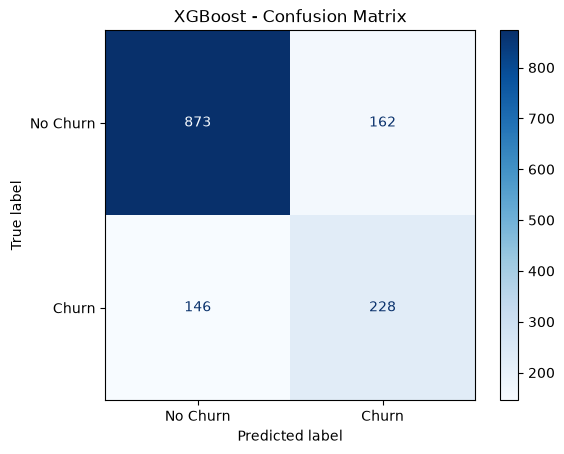

In [31]:
cm_xgb = confusion_matrix(y_test, xgb_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('XGBoost - Confusion Matrix')
plt.show()

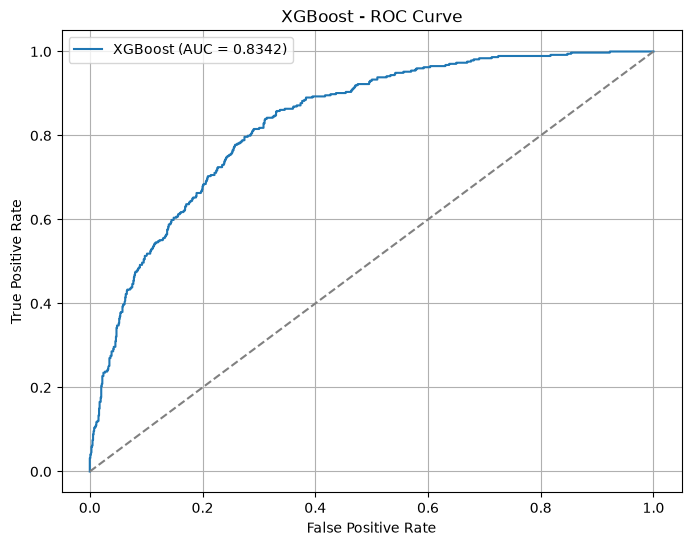

In [32]:
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(
    y_test,
    xgb_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGBoost (AUC = {xgb_roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost - ROC Curve')
plt.legend()
plt.grid()
plt.show()

Model Comparison and ROC Curve Analysis

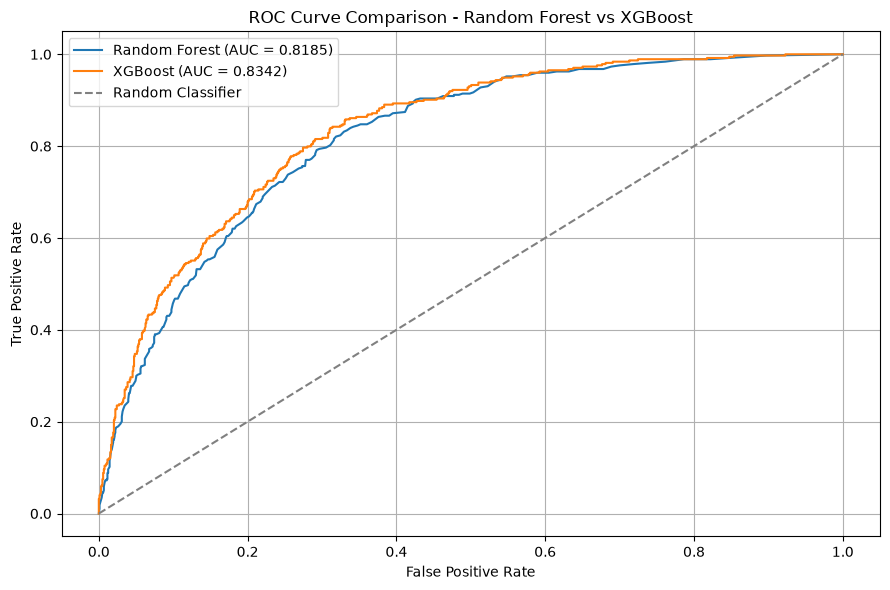

In [34]:
# Calculate ROC curves
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probabilities)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probabilities)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_rf, tpr_rf,
    label=f'Random Forest (AUC = {rf_roc_auc:.4f})'
)

plt.plot(
    fpr_xgb, tpr_xgb,
    label=f'XGBoost (AUC = {xgb_roc_auc:.4f})'
)

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Random Forest vs XGBoost')

plt.legend()
plt.grid()
plt.tight_layout()



plt.show()

In [40]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [rf_accuracy, xgb_accuracy],
    'Precision': [rf_precision, xgb_precision],
    'Recall': [rf_recall, xgb_recall],
    'F1 Score': [rf_f1, xgb_f1],
    'ROC-AUC': [rf_roc_auc, xgb_roc_auc]
})

display(comparison.round(4).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7736,0.5766,0.5535,0.5648,0.8185
1,XGBoost,0.7814,0.5846,0.6096,0.5969,0.8342


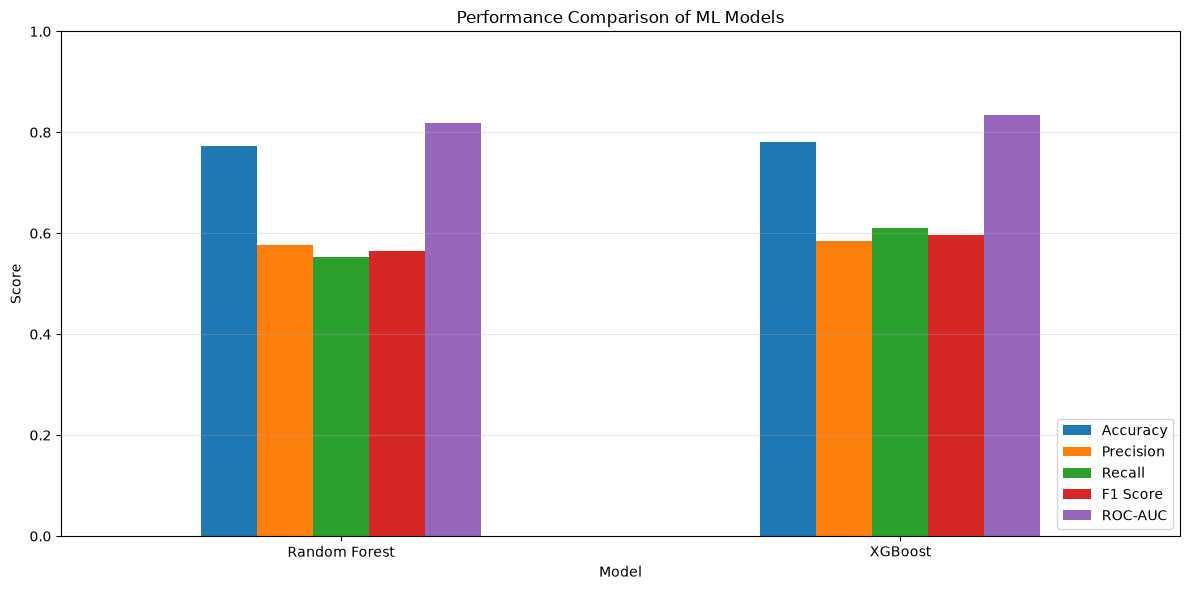

In [38]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of ML Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [41]:
# Get feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Random Forest Features:")
display(rf_importance.head(15))

Top 15 Random Forest Features:


,Feature,Importance
1,num__tenure,0.110427
3,num__TotalCharges,0.110005
2,num__MonthlyCharges,0.096728
36,cat__Contract_Month-to-month,0.078923
18,cat__OnlineSecurity_No,0.054848
43,cat__PaymentMethod_Electronic check,0.046882
27,cat__TechSupport_No,0.041744
38,cat__Contract_Two year,0.036799
16,cat__InternetService_Fiber optic,0.026787
21,cat__OnlineBackup_No,0.021670


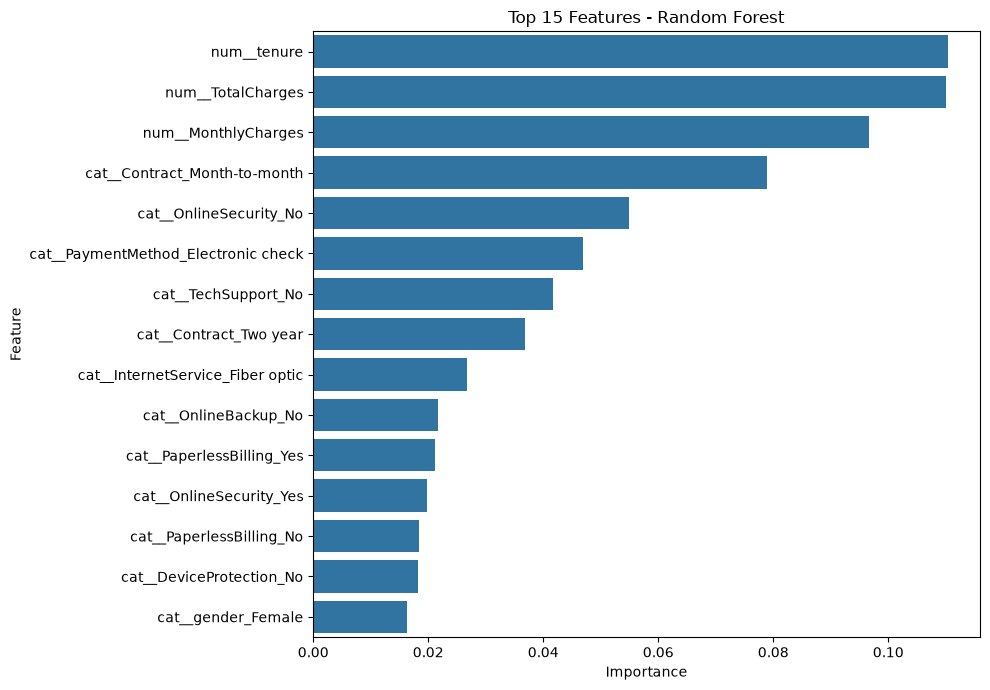

In [43]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features - Random Forest')
plt.tight_layout()

plt.show()

In [44]:
xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 XGBoost Features:")
display(xgb_importance.head(15))

Top 15 XGBoost Features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.286205
18,cat__OnlineSecurity_No,0.085740
16,cat__InternetService_Fiber optic,0.066385
43,cat__PaymentMethod_Electronic check,0.047845
38,cat__Contract_Two year,0.036914
27,cat__TechSupport_No,0.031567
21,cat__OnlineBackup_No,0.023492
15,cat__InternetService_DSL,0.021461
13,cat__MultipleLines_No phone service,0.019837
35,cat__StreamingMovies_Yes,0.019743


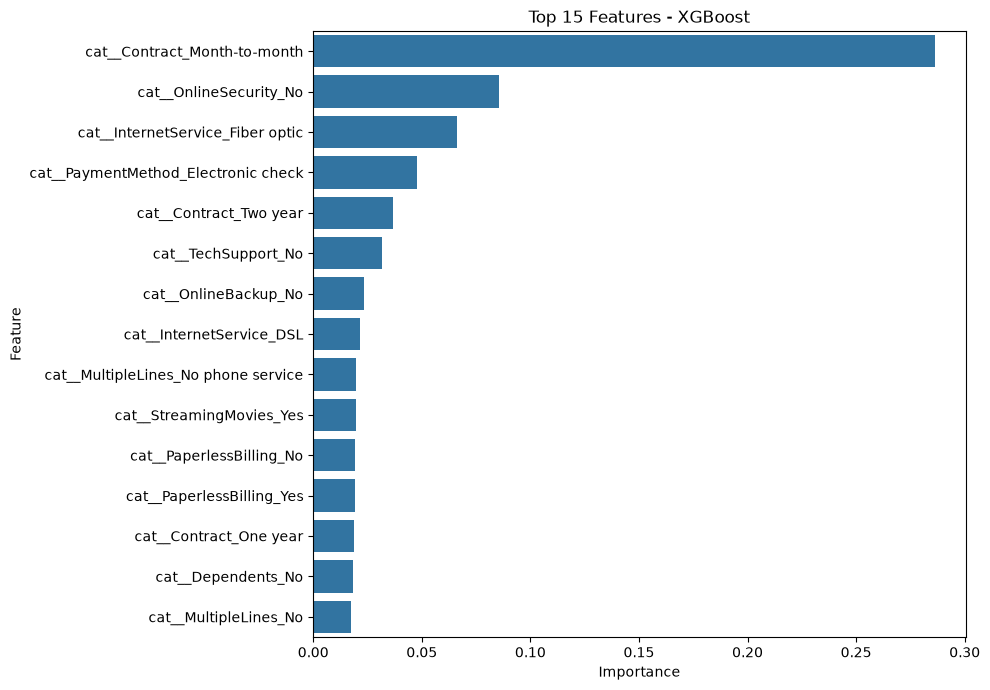

In [46]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=xgb_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features - XGBoost')
plt.tight_layout()

plt.show()

Save Trained Models and Results

In [47]:
import joblib
import os

# Create output directories if they don't exist
os.makedirs('outputs/models', exist_ok=True)
os.makedirs('outputs/plots', exist_ok=True)

print("Output directories ready!")

Output directories ready!


In [48]:
# Save Random Forest model
joblib.dump(
    rf_model,
    'outputs/models/random_forest_model.pkl'
)

# Save XGBoost model
joblib.dump(
    xgb_model,
    'outputs/models/xgboost_model.pkl'
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    'outputs/models/preprocessor.pkl'
)

print("All models and preprocessing pipeline saved successfully!")

All models and preprocessing pipeline saved successfully!


In [49]:
# Save model comparison
comparison.to_csv(
    'outputs/model_comparison.csv',
    index=False
)

# Save Random Forest feature importance
rf_importance.to_csv(
    'outputs/random_forest_feature_importance.csv',
    index=False
)

# Save XGBoost feature importance
xgb_importance.to_csv(
    'outputs/xgboost_feature_importance.csv',
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [50]:
for root, dirs, files in os.walk('outputs'):
    for file in files:
        print(os.path.join(root, file))

outputs\model_comparison.csv
outputs\random_forest_feature_importance.csv
outputs\xgboost_feature_importance.csv
outputs\models\preprocessor.pkl
outputs\models\random_forest_model.pkl
outputs\models\xgboost_model.pkl
